In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/domestic-flight-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv


In [2]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ============================================
# 2. FIND DATA FILES
# ============================================

for path in Path("/kaggle/input").rglob("*"):
    print(path)

/kaggle/input/competitions
/kaggle/input/competitions/domestic-flight-price-prediction-challenge
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv


In [4]:
# ============================================
# 3. LOAD DATA
# ============================================

DATA_PATH = "/kaggle/input/competitions/domestic-flight-price-prediction-challenge"

train_df = pd.read_csv(f"{DATA_PATH}/train.csv")
test_df = pd.read_csv(f"{DATA_PATH}/test.csv")
sample_submission = pd.read_csv(
    f"{DATA_PATH}/sample_submission.csv"
)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Sample submission shape:", sample_submission.shape)

Training shape: (15589, 12)
Test shape: (3898, 11)
Sample submission shape: (3898, 2)


In [5]:
# ============================================
# 4. FIRST LOOK
# ============================================

print("TRAINING DATA")
display(train_df.head())

print("\nTEST DATA")
display(test_df.head())

print("\nSAMPLE SUBMISSION")
display(sample_submission.head())

TRAINING DATA


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842



TEST DATA


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left
0,1,NaN,6E 6017,Springfield,Evening,one,Night,Hill Valley,Economy,5.25,23
1,2,Wayfarer Aviation,AI 2951,Metropolis,Afternoon,zero,Afternoon,Night City,Economy,2.33,46
2,3,Oceanic Airlines,6E 6140,Gotham,Late_Night,one,Early_Morning,Los Santos,Business,4.83,16
3,4,Oceanic Airlines,6E 495,Gotham,Early_Morning,one,Afternoon,Metropolis,Business,5.33,7
4,5,Oceanic Airlines,6E 796,Gotham,Night,zero,Night,Springfield,Economy,1.00,19



SAMPLE SUBMISSION


,id,price
0,1,0.0
1,2,0.0
2,3,0.0
3,4,0.0
4,5,0.0


In [6]:
# ============================================
# 5. BASIC DATASET INFORMATION
# ============================================

print("TRAINING DATA")
print(train_df.info())

print("\nTEST DATA")
print(test_df.info())

TRAINING DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                15589 non-null  int64  
 1   airline           12500 non-null  object 
 2   flight            15589 non-null  object 
 3   source_city       15589 non-null  object 
 4   departure_time    15589 non-null  object 
 5   stops             15589 non-null  object 
 6   arrival_time      15589 non-null  object 
 7   destination_city  15589 non-null  object 
 8   flight_class      15589 non-null  object 
 9   duration          12494 non-null  float64
 10  days_left         15589 non-null  int64  
 11  price             15589 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 1.4+ MB
None

TEST DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3898 entries, 0 to 3897
Data columns (total 11 columns):
 #   Column            Non-Null Co

In [7]:
# ============================================
# 6. FEATURE TYPES
# ============================================

target = "price"

categorical_features = [
    "airline",
    "flight",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "flight_class"
]

numerical_features = [
    "duration",
    "days_left"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTarget:")
print(target)

Categorical features:
['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class']

Numerical features:
['duration', 'days_left']

Target:
price


In [8]:
# ============================================
# 7. MISSING VALUE ANALYSIS
# ============================================

missing_summary = pd.DataFrame({
    "Missing Count": train_df.isnull().sum(),
    "Missing Percentage": (
        train_df.isnull().mean() * 100
    ).round(2),
    "Data Type": train_df.dtypes.astype(str)
})

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage,Data Type
duration,3095,19.85,float64
airline,3089,19.82,object
flight,0,0.00,object
id,0,0.00,int64
source_city,0,0.00,object
departure_time,0,0.00,object
arrival_time,0,0.00,object
stops,0,0.00,object
destination_city,0,0.00,object
flight_class,0,0.00,object


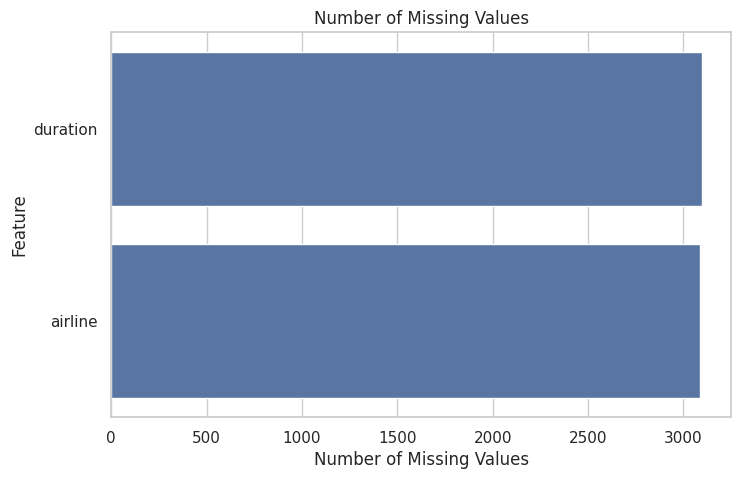

In [9]:
# ============================================
# 8. MISSING VALUE PLOT
# ============================================

missing_plot = (
    train_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_plot = missing_plot[
    missing_plot > 0
]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=missing_plot.values,
    y=missing_plot.index
)

plt.title("Number of Missing Values")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")

plt.show()

In [10]:
# ============================================
# 9. AIRLINE MISSINGNESS ANALYSIS
# ============================================

train_df["airline_missing"] = (
    train_df["airline"].isna()
)

display(
    train_df.groupby(
        "airline_missing"
    )["price"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

,count,mean,median,std,min,max
airline_missing,,,,,,
False,12500,29685.42,10183.0,38996.24,3801,323177
True,3089,30347.94,10213.0,39658.11,3895,288886


In [11]:
# ============================================
# 10. DURATION MISSINGNESS ANALYSIS
# ============================================

train_df["duration_missing"] = (
    train_df["duration"].isna()
)

display(
    train_df.groupby(
        "duration_missing"
    )["price"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

,count,mean,median,std,min,max
duration_missing,,,,,,
False,12494,29845.23,10183.0,39339.52,3801,323177
True,3095,29701.49,10269.0,38267.71,3801,266471


In [12]:
# ============================================
# 11. MISSING DURATION BY ROUTE
# ============================================

duration_missing_route = (
    train_df[
        train_df["duration"].isna()
    ]
    .groupby([
        "source_city",
        "destination_city"
    ])
    .size()
    .sort_values(ascending=False)
)

display(
    duration_missing_route.head(20)
)

source_city  destination_city
Metropolis   Night City          699
             Springfield         268
Night City   Metropolis          191
Springfield  Metropolis          146
Metropolis   Hill Valley         131
Night City   Springfield         128
             Hill Valley          92
             Gotham               86
Springfield  Gotham               84
Gotham       Metropolis           78
Hill Valley  Metropolis           75
Night City   Los Santos           72
Los Santos   Night City           68
             Metropolis           68
Hill Valley  Springfield          68
Springfield  Los Santos           65
Gotham       Night City           64
Springfield  Hill Valley          63
Metropolis   Gotham               61
Hill Valley  Los Santos           61
dtype: int64

In [13]:
# ============================================
# 12. MISSING DURATION BY STOPS
# ============================================

display(
    pd.crosstab(
        train_df["duration_missing"],
        train_df["stops"],
        normalize="index"
    ).round(3)
)

stops,one,two_or_more,zero
duration_missing,,,
False,0.293,0.005,0.703
True,0.290,0.003,0.707


In [14]:
# ============================================
# 13. MISSING AIRLINE BY FLIGHT CLASS
# ============================================

display(
    pd.crosstab(
        train_df["airline_missing"],
        train_df["flight_class"],
        normalize="index"
    ).round(3)
)

flight_class,Business,Economy
airline_missing,,
False,0.408,0.592
True,0.412,0.588


In [15]:
# ============================================
# 14. MISSING AIRLINE BY SOURCE CITY
# ============================================

display(
    pd.crosstab(
        train_df["airline_missing"],
        train_df["source_city"],
        normalize="index"
    ).round(3)
)

source_city,Gotham,Hill Valley,Los Santos,Metropolis,Night City,Springfield
airline_missing,,,,,,
False,0.103,0.102,0.096,0.396,0.172,0.130
True,0.095,0.103,0.099,0.402,0.164,0.137


In [16]:
# ============================================
# 15. MISSING AIRLINE BY DESTINATION CITY
# ============================================

display(
    pd.crosstab(
        train_df["airline_missing"],
        train_df["destination_city"],
        normalize="index"
    ).round(3)
)

destination_city,Gotham,Hill Valley,Los Santos,Metropolis,Night City,Springfield
airline_missing,,,,,,
False,0.100,0.137,0.103,0.178,0.298,0.184
True,0.102,0.133,0.105,0.172,0.302,0.186


In [17]:
# ============================================
# 16. DURATION BY ROUTE
# ============================================

route_duration = (
    train_df[
        train_df["duration"].notna()
    ]
    .groupby([
        "source_city",
        "destination_city"
    ])["duration"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(
    route_duration
    .sort_values("count", ascending=False)
    .head(20)
    .round(2)
)

count  mean  median   std   min    max
source_city destination_city                                        
Metropolis  Night City         2867  2.71    2.42  1.48  2.17  20.92
            Springfield         916  3.42    2.92  1.89  2.00  21.25
            Hill Valley         696  3.01    2.33  1.96  2.17  22.08
Springfield Metropolis          676  3.55    2.92  1.68  2.75  21.83
Night City  Metropolis          651  2.49    2.33  1.11  2.17  21.08
            Springfield         562  2.58    2.08  2.20  1.67  28.08
            Hill Valley         367  4.66    2.92  3.76  2.67  23.08
Hill Valley Springfield         327  7.22    5.92  5.34  1.92  22.50
            Metropolis          320  3.46    2.50  2.92  2.25  29.67
Gotham      Metropolis          280  4.19    3.00  2.32  2.75  25.83
Springfield Los Santos          276  6.93    5.25  5.90  1.17  36.00
Los Santos  Metropolis          274  3.15    2.50  1.59  2.25  18.00
Gotham      Los Santos          271  7.65    5.75  6.22  1.25  27.92
Metropolis  Gotham              257  4.51    2.92  2.82  2.67  25.42
Night City  Gotham              255  3.68    2.25  2.96  2.00  21.08
Hill Valley Los Santos          254  9.44    6.75  7.20  2.08  38.08
Gotham      Springfield         252  8.81    9.50  7.44  1.00  24.92
            Night City          248  2.69    2.21  1.66  1.83  21.83
Night City  Los Santos          247  3.21    1.58  3.77  1.42  20.50
Springfield Gotham              246  7.13    5.67  6.26  0.92  26.58

In [18]:
# ============================================
# 16. DURATION BY ROUTE
# ============================================

route_duration = (
    train_df[
        train_df["duration"].notna()
    ]
    .groupby([
        "source_city",
        "destination_city"
    ])["duration"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(
    route_duration
    .sort_values("count", ascending=False)
    .head(20)
    .round(2)
)

count  mean  median   std   min    max
source_city destination_city                                        
Metropolis  Night City         2867  2.71    2.42  1.48  2.17  20.92
            Springfield         916  3.42    2.92  1.89  2.00  21.25
            Hill Valley         696  3.01    2.33  1.96  2.17  22.08
Springfield Metropolis          676  3.55    2.92  1.68  2.75  21.83
Night City  Metropolis          651  2.49    2.33  1.11  2.17  21.08
            Springfield         562  2.58    2.08  2.20  1.67  28.08
            Hill Valley         367  4.66    2.92  3.76  2.67  23.08
Hill Valley Springfield         327  7.22    5.92  5.34  1.92  22.50
            Metropolis          320  3.46    2.50  2.92  2.25  29.67
Gotham      Metropolis          280  4.19    3.00  2.32  2.75  25.83
Springfield Los Santos          276  6.93    5.25  5.90  1.17  36.00
Los Santos  Metropolis          274  3.15    2.50  1.59  2.25  18.00
Gotham      Los Santos          271  7.65    5.75  6.22  1.25  27.92
Metropolis  Gotham              257  4.51    2.92  2.82  2.67  25.42
Night City  Gotham              255  3.68    2.25  2.96  2.00  21.08
Hill Valley Los Santos          254  9.44    6.75  7.20  2.08  38.08
Gotham      Springfield         252  8.81    9.50  7.44  1.00  24.92
            Night City          248  2.69    2.21  1.66  1.83  21.83
Night City  Los Santos          247  3.21    1.58  3.77  1.42  20.50
Springfield Gotham              246  7.13    5.67  6.26  0.92  26.58

In [19]:
train_df.drop(
    columns=[
        "airline_missing",
        "duration_missing"
    ],
    inplace=True
)

In [20]:
# ============================================
# 18. PRICE STATISTICS
# ============================================

display(
    train_df["price"].describe().to_frame()
)

,price
count,15589.000000
mean,29816.695555
std,39127.890925
min,3801.000000
25%,7210.000000
50%,10183.000000
75%,35968.000000
max,323177.000000


In [21]:
price_stats = pd.DataFrame({
    "Mean": [train_df["price"].mean()],
    "Median": [train_df["price"].median()],
    "Std": [train_df["price"].std()],
    "Minimum": [train_df["price"].min()],
    "Maximum": [train_df["price"].max()],
    "Skewness": [train_df["price"].skew()]
})

display(price_stats.round(2))

,Mean,Median,Std,Minimum,Maximum,Skewness
0,29816.7,10183.0,39127.89,3801,323177,2.7


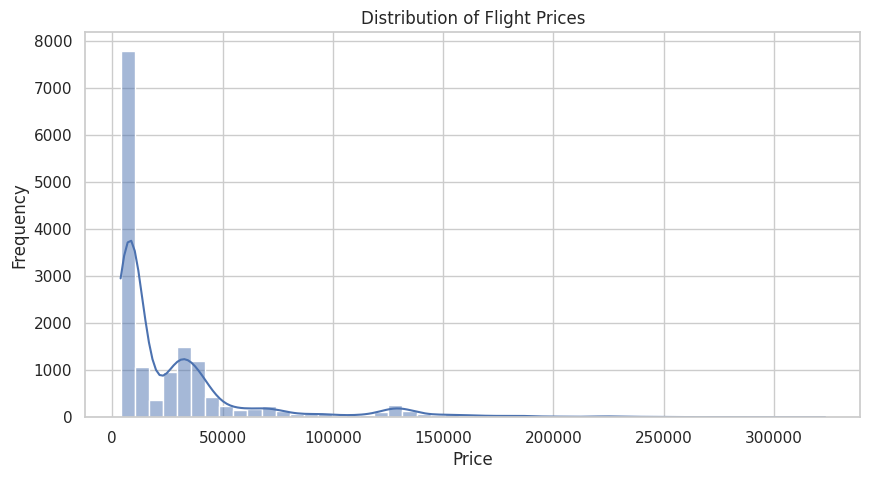

In [22]:
# ============================================
# 19. PRICE DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["price"],
    bins=50,
    kde=True
)

plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

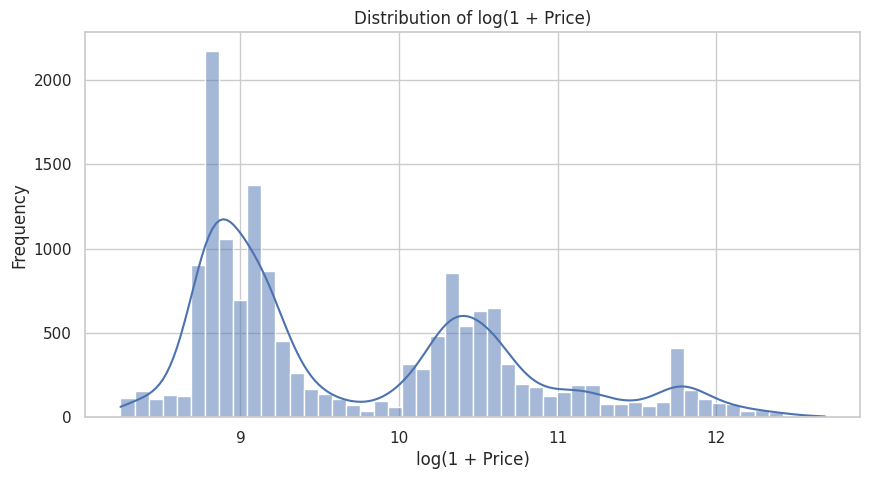

Original skewness: 2.704
Log-transformed skewness: 0.715


In [23]:
# ============================================
# 20. LOG PRICE DISTRIBUTION
# ============================================

log_price = np.log1p(
    train_df["price"]
)

plt.figure(figsize=(10, 5))

sns.histplot(
    log_price,
    bins=50,
    kde=True
)

plt.title("Distribution of log(1 + Price)")
plt.xlabel("log(1 + Price)")
plt.ylabel("Frequency")

plt.show()

print(
    "Original skewness:",
    round(train_df["price"].skew(), 3)
)

print(
    "Log-transformed skewness:",
    round(log_price.skew(), 3)
)

In [24]:
# ============================================
# 21. NUMERICAL FEATURES
# ============================================

numerical_features = [
    "duration",
    "days_left"
]

display(
    train_df[numerical_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
duration,12494.0,4.300499,4.181832,0.92,2.25,2.5,4.92,38.08
days_left,15589.0,22.461928,13.036812,1.00,12.00,22.0,33.00,57.00


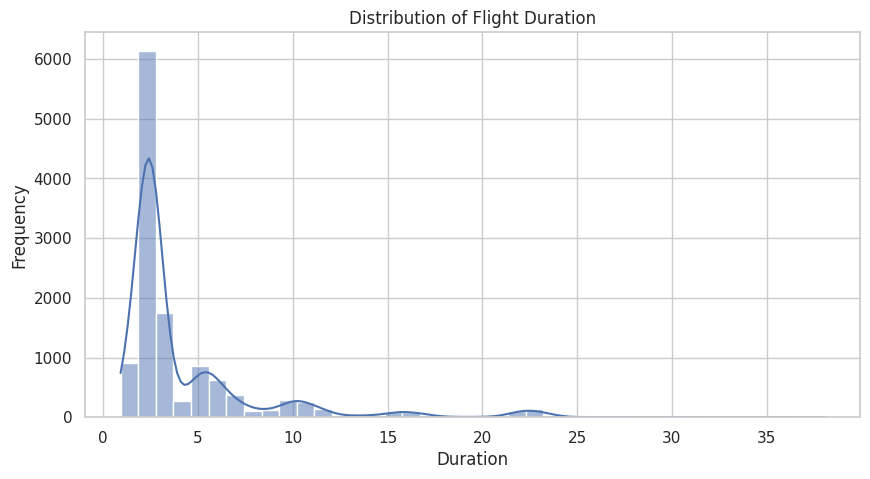

In [25]:
# ============================================
# 22. DURATION DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="duration",
    bins=40,
    kde=True
)

plt.title("Distribution of Flight Duration")
plt.xlabel("Duration")
plt.ylabel("Frequency")

plt.show()

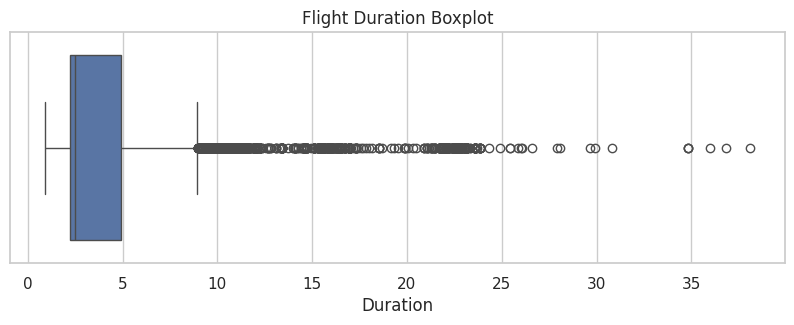

In [26]:
# ============================================
# 23. DURATION BOXPLOT
# ============================================

plt.figure(figsize=(10, 3))

sns.boxplot(
    x=train_df["duration"]
)

plt.title("Flight Duration Boxplot")
plt.xlabel("Duration")

plt.show()

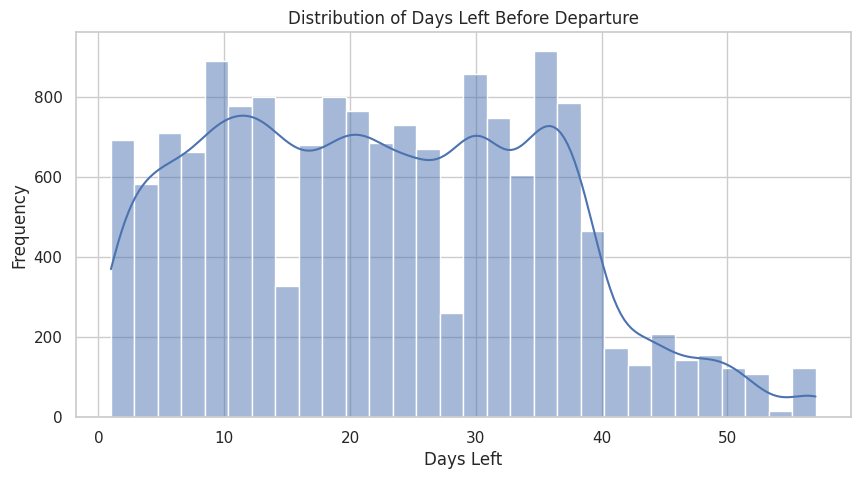

In [27]:
# ============================================
# 24. DAYS LEFT DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["days_left"],
    bins=30,
    kde=True
)

plt.title("Distribution of Days Left Before Departure")
plt.xlabel("Days Left")
plt.ylabel("Frequency")

plt.show()

In [28]:
categorical_features = [
    "airline",
    "flight",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "flight_class"
]

In [29]:
# ============================================
# 25. CATEGORICAL CARDINALITY
# ============================================

cardinality = pd.DataFrame({
    "Feature": categorical_features,
    "Unique Values": [
        train_df[col].nunique(dropna=False)
        for col in categorical_features
    ],
    "Missing Values": [
        train_df[col].isna().sum()
        for col in categorical_features
    ]
})

display(cardinality)

,Feature,Unique Values,Missing Values
0,airline,19,3089
1,flight,1070,0
2,source_city,6,0
3,departure_time,6,0
4,stops,3,0
5,arrival_time,6,0
6,destination_city,6,0
7,flight_class,2,0


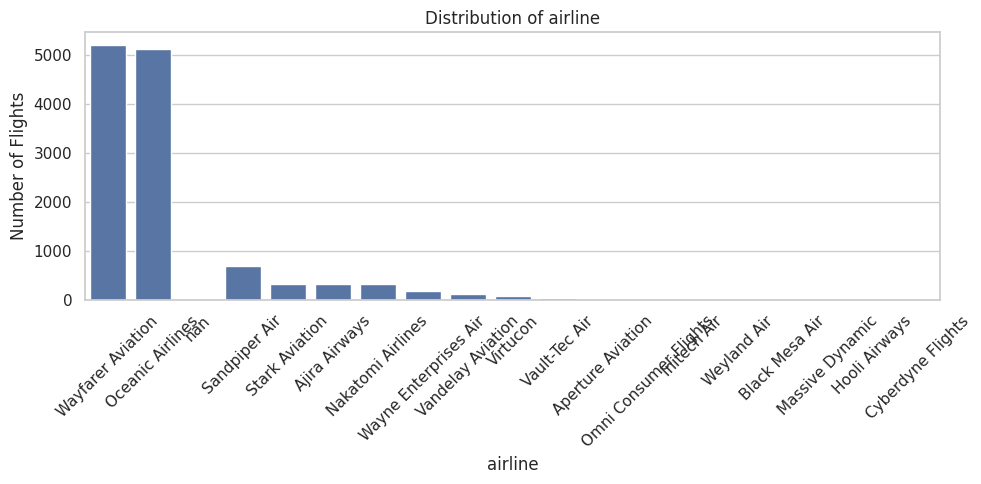

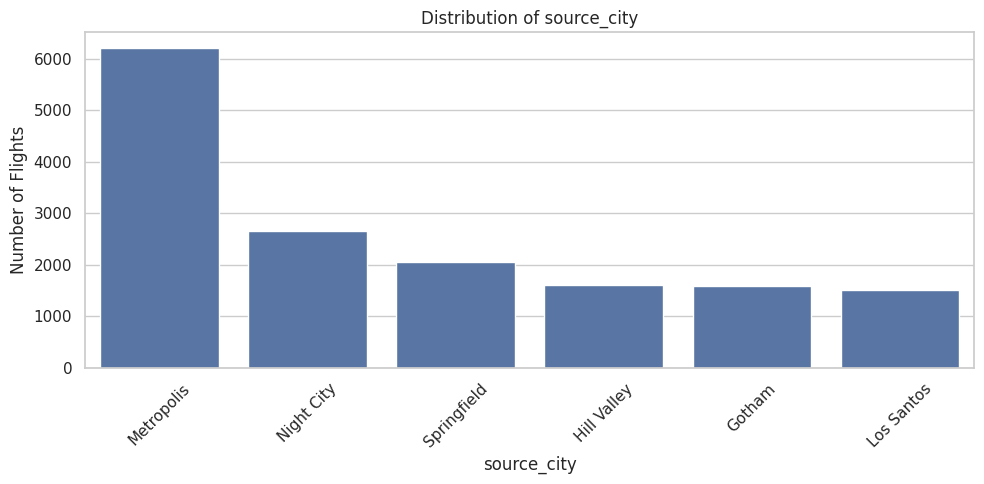

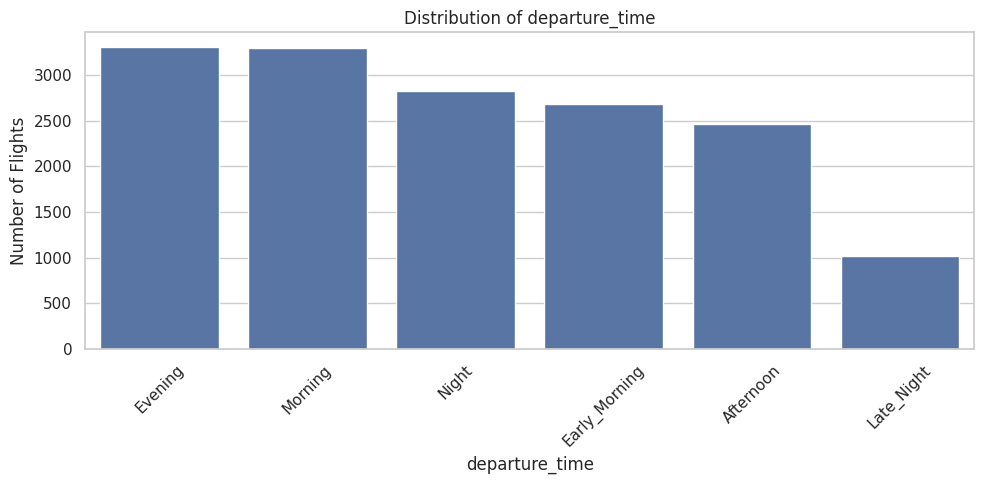

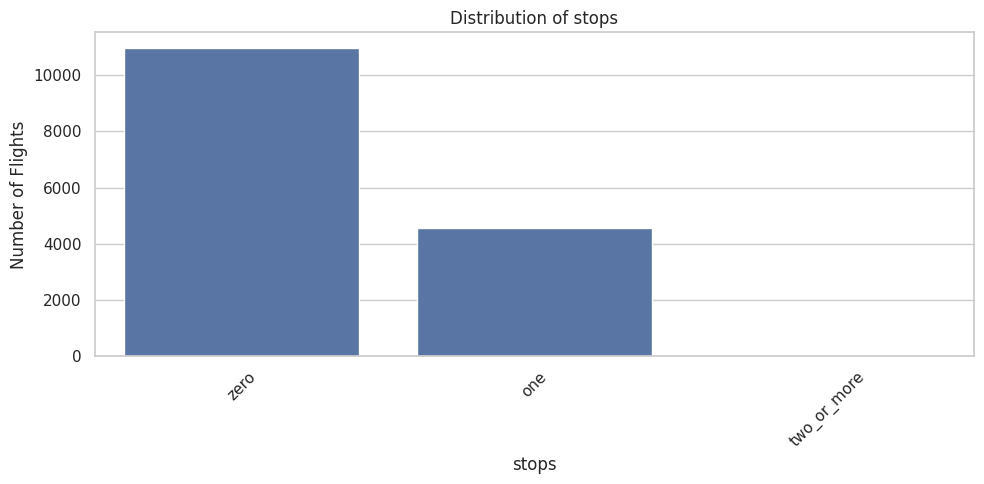

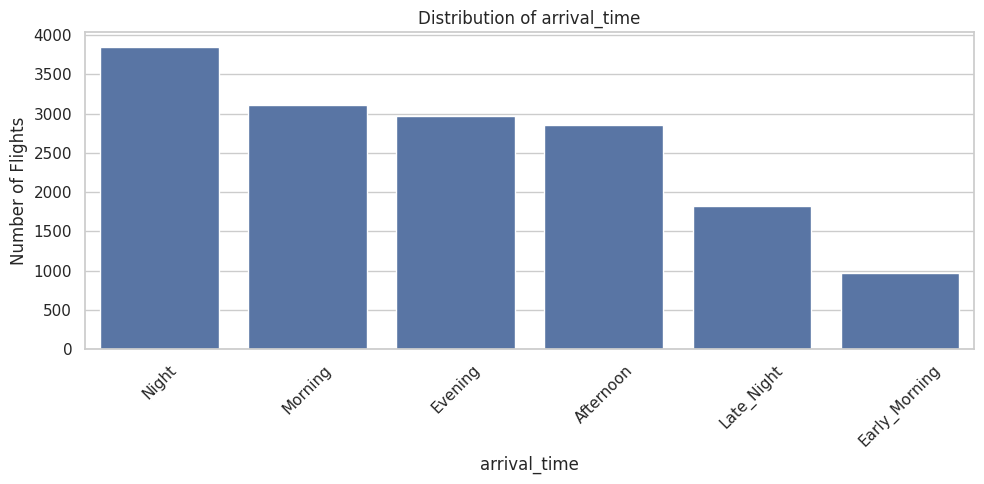

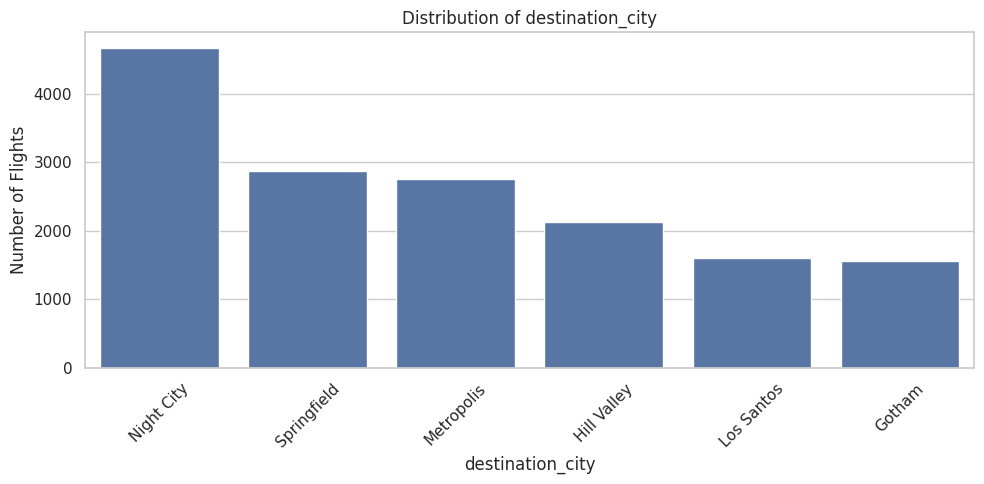

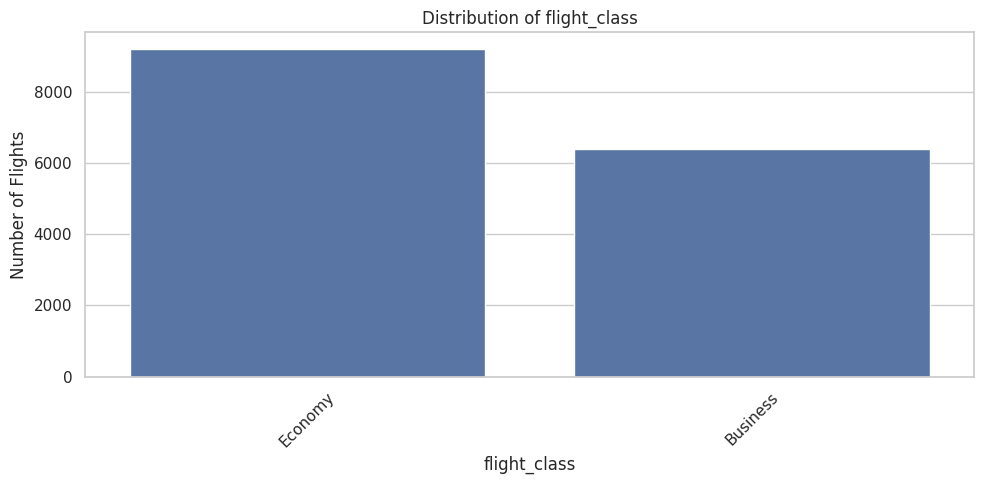

In [30]:
# ============================================
# 26. CATEGORICAL DISTRIBUTIONS
# ============================================

plot_features = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "flight_class"
]

for feature in plot_features:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=train_df,
        x=feature,
        order=train_df[feature]
            .value_counts(dropna=False)
            .index
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Flights")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

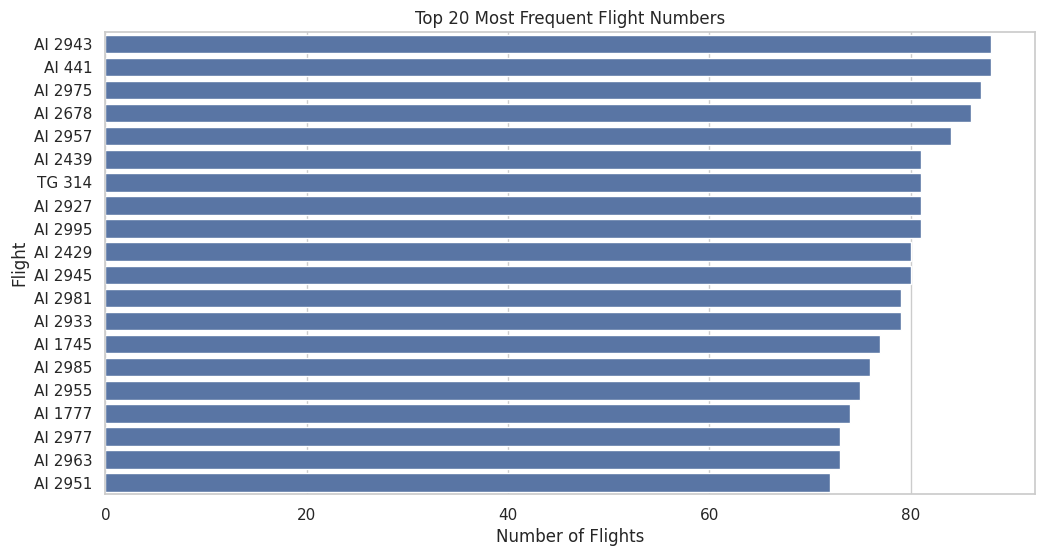

In [31]:
# ============================================
# 27. TOP 20 FLIGHTS
# ============================================

top_flights = (
    train_df["flight"]
    .value_counts()
    .head(20)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_flights.values,
    y=top_flights.index
)

plt.title("Top 20 Most Frequent Flight Numbers")
plt.xlabel("Number of Flights")
plt.ylabel("Flight")

plt.show()

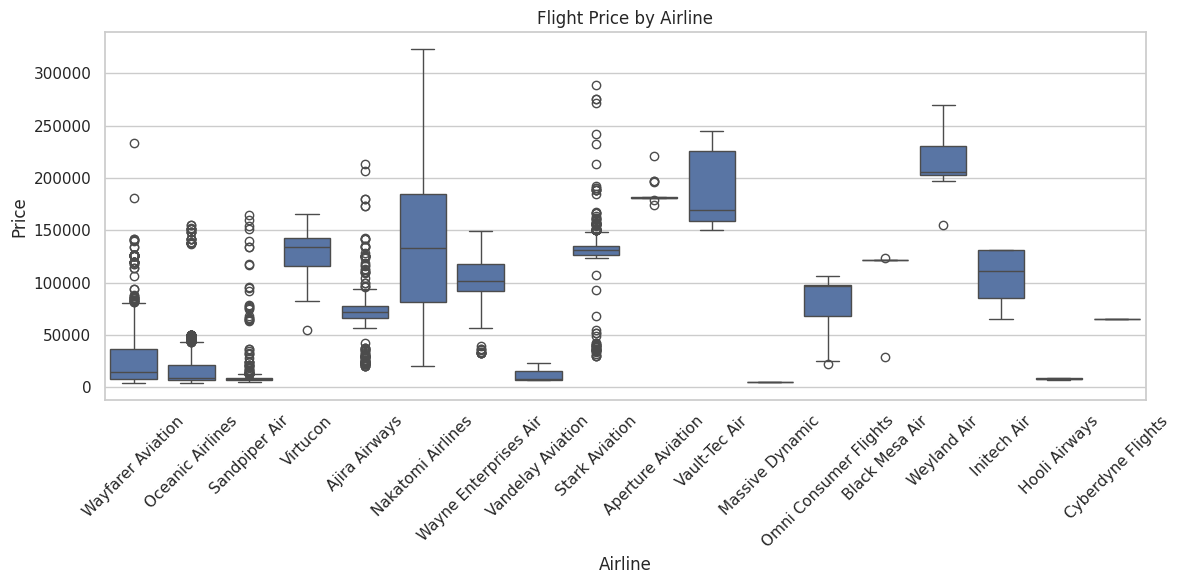

In [32]:
# ============================================
# 28. PRICE BY AIRLINE
# ============================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=train_df,
    x="airline",
    y="price"
)

plt.title("Flight Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Price")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

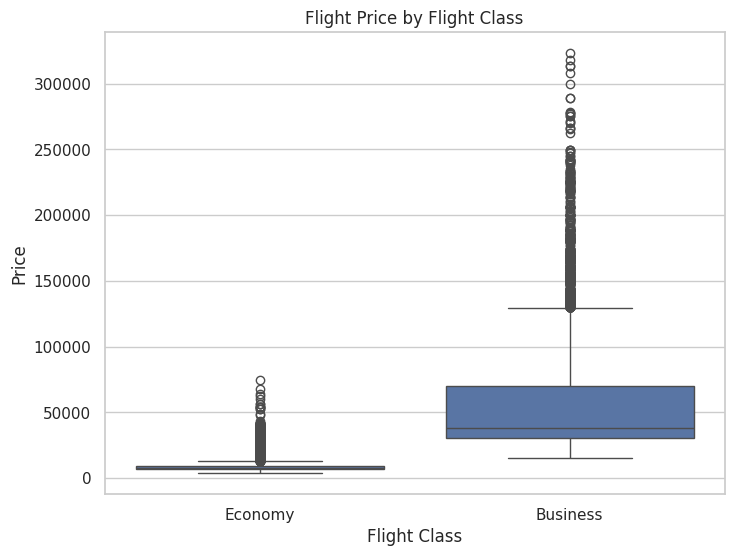

In [33]:
# ============================================
# 29. PRICE BY FLIGHT CLASS
# ============================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=train_df,
    x="flight_class",
    y="price"
)

plt.title("Flight Price by Flight Class")
plt.xlabel("Flight Class")
plt.ylabel("Price")

plt.show()

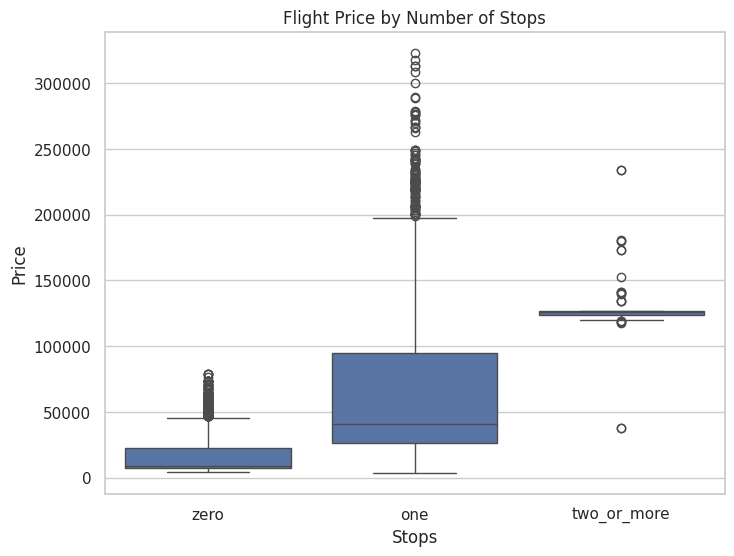

In [34]:
# ============================================
# 30. PRICE BY STOPS
# ============================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=train_df,
    x="stops",
    y="price"
)

plt.title("Flight Price by Number of Stops")
plt.xlabel("Stops")
plt.ylabel("Price")

plt.show()

In [35]:
# ============================================
# 31. ROUTE-LEVEL PRICE ANALYSIS
# ============================================

route_price = (
    train_df
    .groupby([
        "source_city",
        "destination_city"
    ])["price"]
    .agg([
        "count",
        "mean",
        "median",
        "std"
    ])
    .sort_values("median", ascending=False)
)

display(
    route_price.head(20).round(2)
)

count      mean   median       std
source_city destination_city                                    
Gotham      Springfield         311  75446.77  71781.0  65093.61
Springfield Gotham              330  63885.57  59619.0  62501.38
Los Santos  Springfield         290  69678.79  55367.0  70612.46
            Gotham              283  65676.70  53504.0  64526.20
Gotham      Hill Valley         274  64629.57  43881.0  55536.34
Hill Valley Gotham              290  65785.20  43742.0  51287.61
Springfield Hill Valley         286  46091.72  40172.0  48253.98
Hill Valley Night City          205  38299.96  38046.0  35897.80
Los Santos  Hill Valley         280  57857.45  37238.0  55729.47
Hill Valley Los Santos          315  56833.02  37156.0  50889.61
            Springfield         395  44836.65  36619.0  49704.87
Night City  Hill Valley         459  34841.43  30055.0  33126.13
Gotham      Los Santos          331  54843.93  29191.0  53578.89
Metropolis  Gotham              318  27941.07  27621.0  25382.17
Night City  Gotham              341  30729.42  26634.0  29576.46
Springfield Los Santos          341  65498.32  23581.0  72134.84
Night City  Los Santos          319  29940.47  22562.0  38663.77
Los Santos  Night City          308  25652.85  18085.0  38356.70
Springfield Night City          272  23011.82  15469.5  29030.56
Hill Valley Metropolis          395  26125.96  15412.0  27073.93

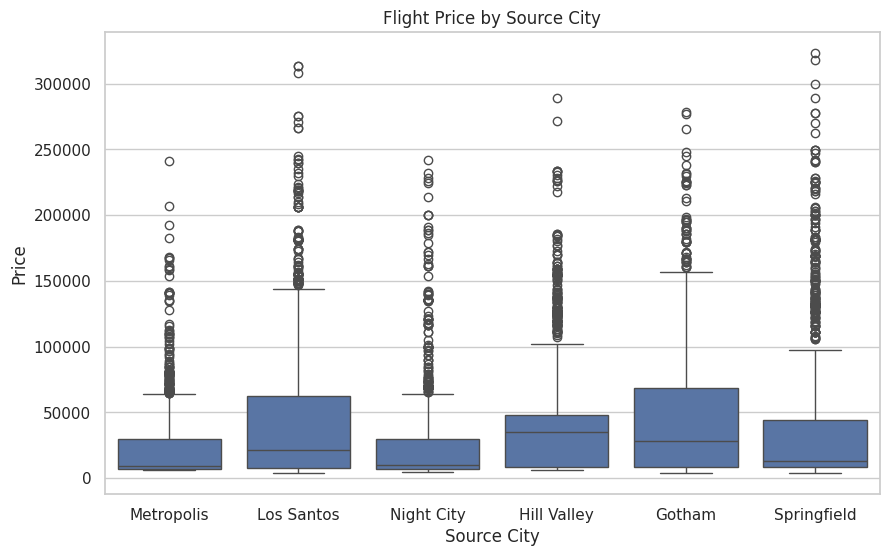

In [36]:
# ============================================
# 32. PRICE BY SOURCE CITY
# ============================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train_df,
    x="source_city",
    y="price"
)

plt.title("Flight Price by Source City")
plt.xlabel("Source City")
plt.ylabel("Price")

plt.show()

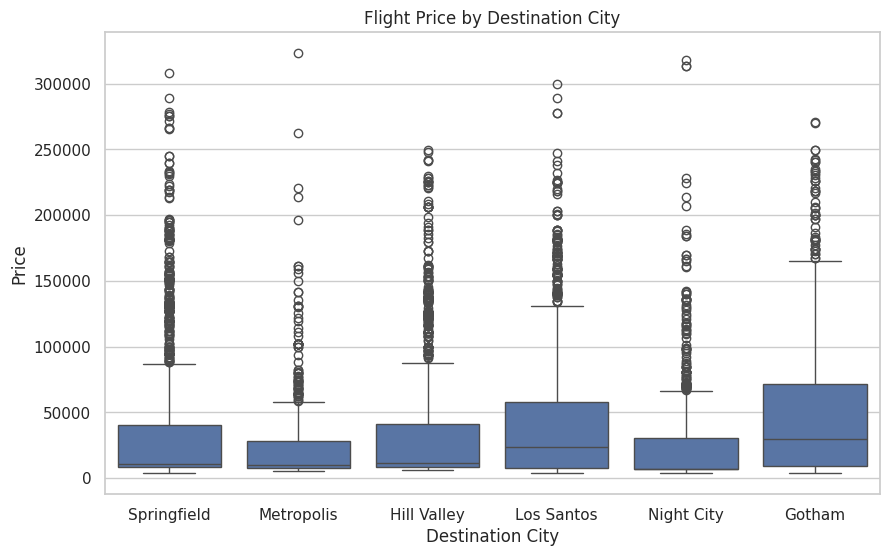

In [37]:
# ============================================
# 33. PRICE BY DESTINATION CITY
# ============================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train_df,
    x="destination_city",
    y="price"
)

plt.title("Flight Price by Destination City")
plt.xlabel("Destination City")
plt.ylabel("Price")

plt.show()

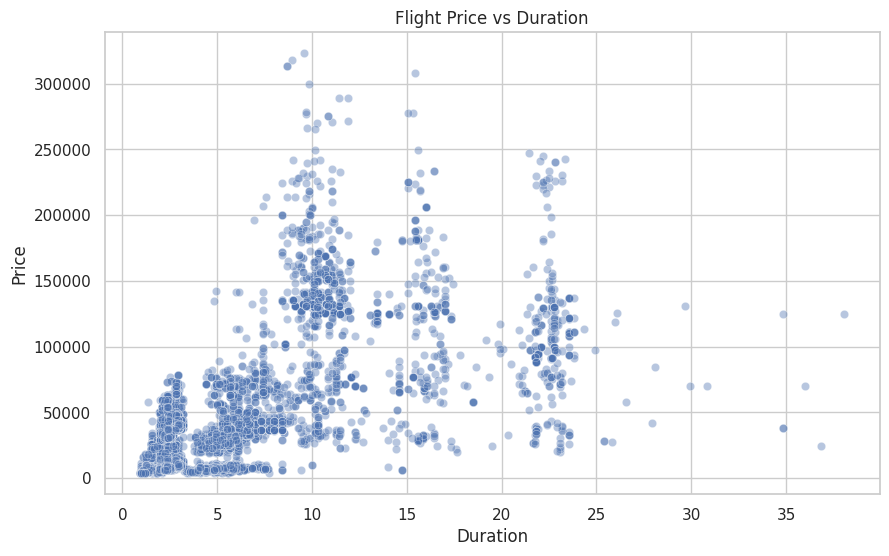

In [38]:
# ============================================
# 34. PRICE VS DURATION
# ============================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train_df,
    x="duration",
    y="price",
    alpha=0.4
)

plt.title("Flight Price vs Duration")
plt.xlabel("Duration")
plt.ylabel("Price")

plt.show()

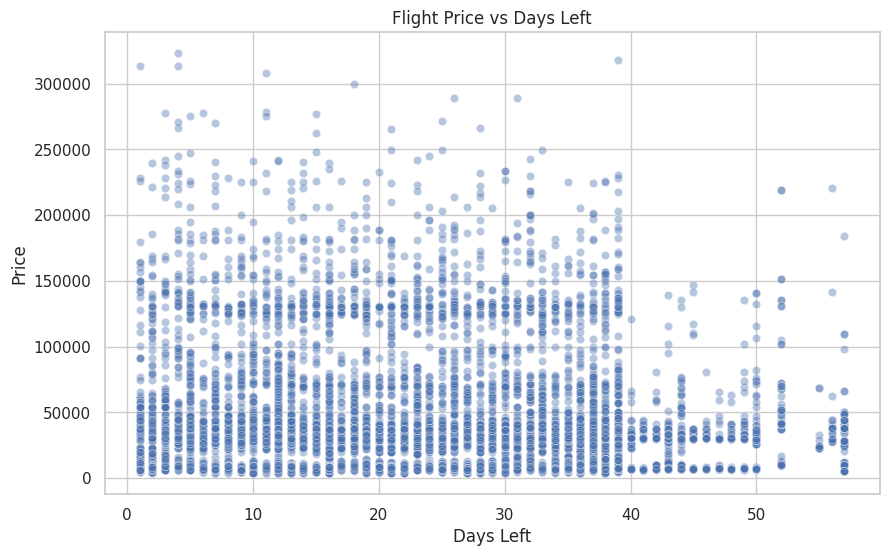

In [39]:
# ============================================
# 35. PRICE VS DAYS LEFT
# ============================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train_df,
    x="days_left",
    y="price",
    alpha=0.4
)

plt.title("Flight Price vs Days Left")
plt.xlabel("Days Left")
plt.ylabel("Price")

plt.show()

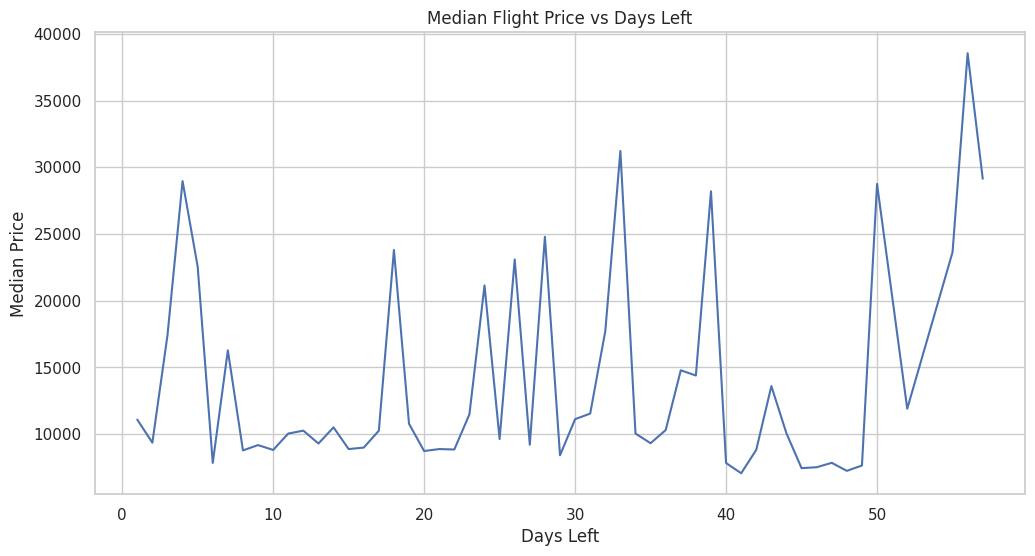

In [40]:
# ============================================
# 36. MEDIAN PRICE VS DAYS LEFT
# ============================================

days_price = (
    train_df
    .groupby("days_left")["price"]
    .median()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=days_price,
    x="days_left",
    y="price"
)

plt.title("Median Flight Price vs Days Left")
plt.xlabel("Days Left")
plt.ylabel("Median Price")

plt.show()

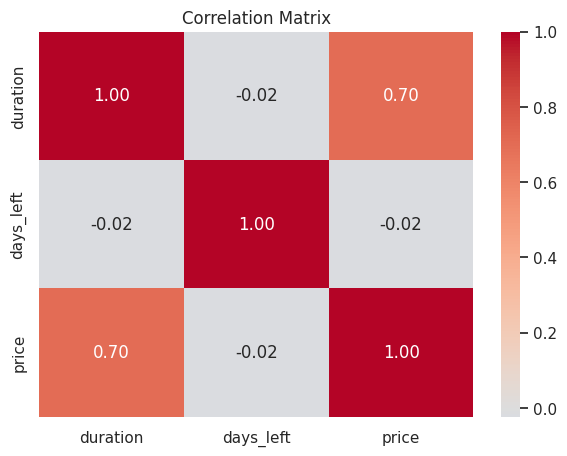

In [41]:
# ============================================
# 37. CORRELATION MATRIX
# ============================================

correlation_features = [
    "duration",
    "days_left",
    "price"
]

correlation_matrix = train_df[
    correlation_features
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.show()

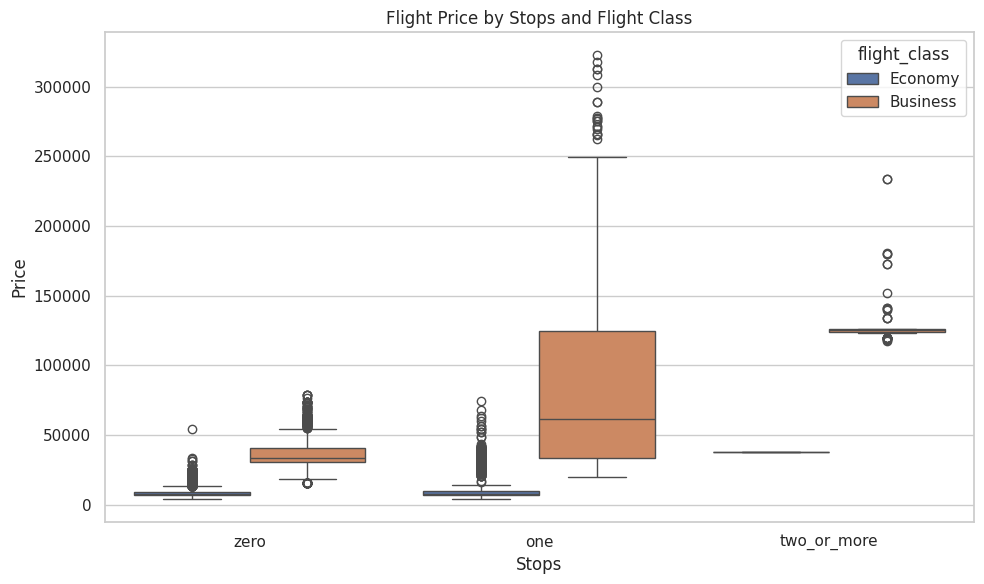

In [42]:
# ============================================
# 38. CLASS × STOPS × PRICE
# ============================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train_df,
    x="stops",
    y="price",
    hue="flight_class"
)

plt.title("Flight Price by Stops and Flight Class")
plt.xlabel("Stops")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

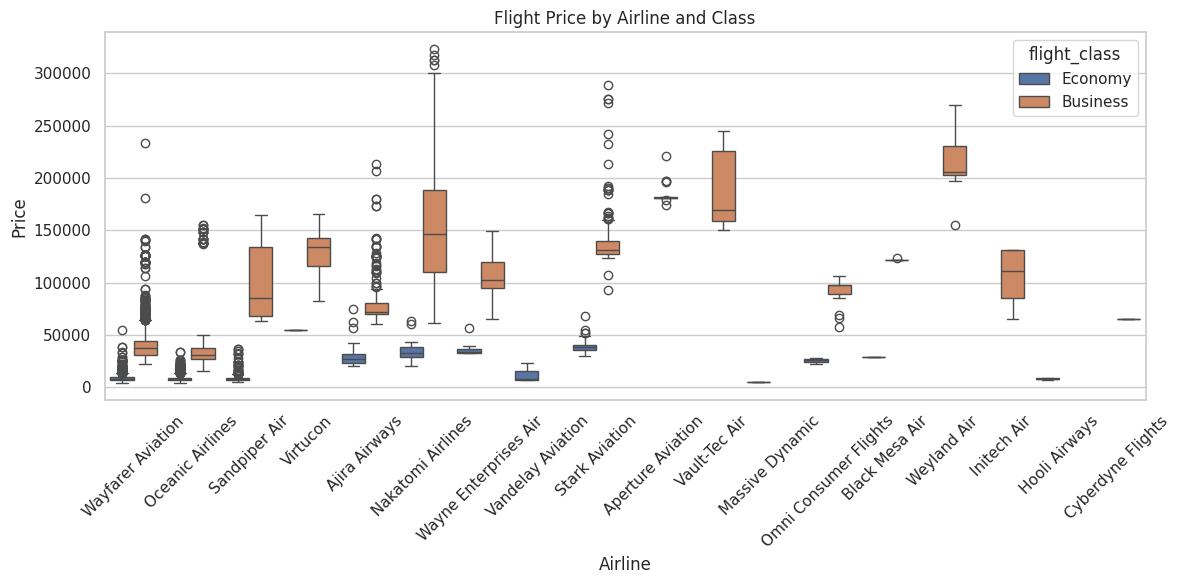

In [43]:
# ============================================
# 39. AIRLINE × CLASS
# ============================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=train_df,
    x="airline",
    y="price",
    hue="flight_class"
)

plt.title("Flight Price by Airline and Class")
plt.xlabel("Airline")
plt.ylabel("Price")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [44]:
# ============================================
# 40. PRICE OUTLIER ANALYSIS
# ============================================

Q1 = train_df["price"].quantile(0.25)
Q3 = train_df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = train_df[
    (train_df["price"] < lower_bound) |
    (train_df["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("Potential outliers:", len(outliers))

print(
    "Percentage:",
    round(
        len(outliers) / len(train_df) * 100,
        2
    )
)

Q1: 7210.0
Q3: 35968.0
IQR: 28758.0
Lower bound: -35927.0
Upper bound: 79105.0
Potential outliers: 1370
Percentage: 8.79


In [45]:
# ============================================
# 41. HIGH PRICE OBSERVATIONS
# ============================================

display(
    train_df
    .sort_values("price", ascending=False)
    .head(20)
)

,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
4996,4997,Nakatomi Airlines,EY 233,Springfield,Early_Morning,one,Afternoon,Metropolis,Business,9.58,4,323177
2541,2542,Nakatomi Airlines,EY 239,Springfield,Night,one,Early_Morning,Night City,Business,8.92,39,317854
15036,15037,Nakatomi Airlines,EY 353,Los Santos,Early_Morning,one,Afternoon,Night City,Business,8.67,4,313132
8831,8832,Nakatomi Airlines,EY 353,Los Santos,Early_Morning,one,Afternoon,Night City,Business,8.67,1,313132
4049,4050,Nakatomi Airlines,EY 353,Los Santos,Early_Morning,one,Evening,Springfield,Business,15.42,11,308302
3384,3385,Nakatomi Airlines,EY 237,Springfield,Evening,one,Late_Night,Los Santos,Business,9.83,18,300148
2858,2859,Stark Aviation,EK 573,Hill Valley,Night,one,Morning,Springfield,Business,11.92,26,289045
3137,3138,NaN,EK 567,Springfield,Night,one,Morning,Los Santos,Business,11.42,31,288886
6453,6454,NaN,EY 343,Gotham,Morning,one,Evening,Springfield,Business,9.67,11,278762
13302,13303,Nakatomi Airlines,EY 233,Springfield,Early_Morning,one,Evening,Los Santos,Business,15.08,6,277593


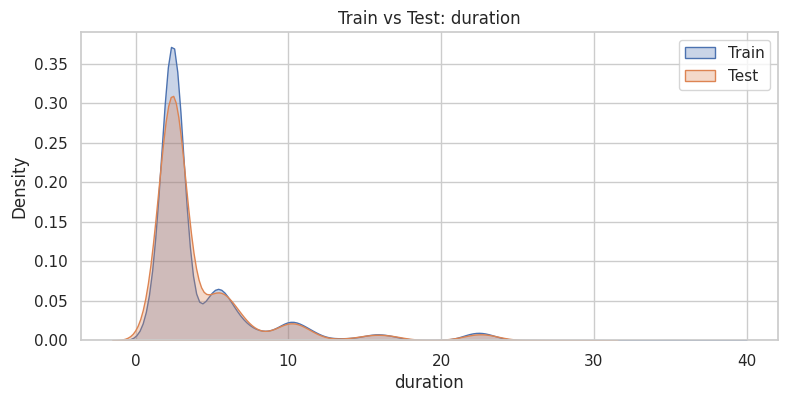

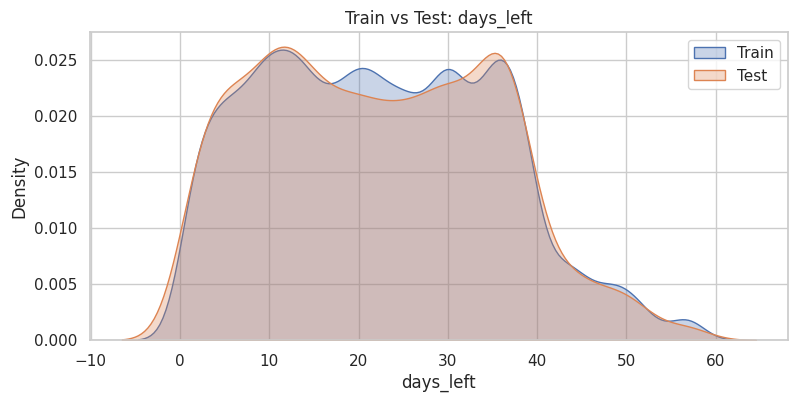

In [46]:
# ============================================
# 42. TRAIN VS TEST NUMERICAL FEATURES
# ============================================

for feature in numerical_features:

    plt.figure(figsize=(9, 4))

    sns.kdeplot(
        train_df[feature].dropna(),
        label="Train",
        fill=True,
        alpha=0.3
    )

    sns.kdeplot(
        test_df[feature].dropna(),
        label="Test",
        fill=True,
        alpha=0.3
    )

    plt.title(f"Train vs Test: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Density")

    plt.legend()
    plt.show()

In [47]:
# ============================================
# 43. TRAIN VS TEST MISSINGNESS
# ============================================

train_missing = (
    train_df.isnull().mean() * 100
)

test_missing = (
    test_df.isnull().mean() * 100
)

missing_comparison = pd.DataFrame({
    "Train Missing %": train_missing,
    "Test Missing %": test_missing
})

display(
    missing_comparison.round(2)
)

,Train Missing %,Test Missing %
airline,19.82,20.50
arrival_time,0.00,0.00
days_left,0.00,0.00
departure_time,0.00,0.00
destination_city,0.00,0.00
duration,19.85,19.91
flight,0.00,0.00
flight_class,0.00,0.00
id,0.00,0.00
price,0.00,NaN


In [48]:
# ============================================
# 44. TRAIN VS TEST CATEGORICAL DISTRIBUTION
# ============================================

def compare_categorical_distribution(
    train,
    test,
    feature
):

    train_dist = (
        train[feature]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .rename("Train")
    )

    test_dist = (
        test[feature]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .rename("Test")
    )

    comparison = pd.concat(
        [train_dist, test_dist],
        axis=1
    ).fillna(0)

    comparison["Absolute Difference"] = (
        comparison["Test"] -
        comparison["Train"]
    ).abs()

    return comparison.sort_values(
        "Absolute Difference",
        ascending=False
    )


for feature in [
    "airline",
    "source_city",
    "destination_city",
    "flight_class",
    "stops"
]:

    print("\n" + "=" * 60)
    print(feature)
    print("=" * 60)

    display(
        compare_categorical_distribution(
            train_df,
            test_df,
            feature
        ).round(4)
    )


airline


,Train,Test,Absolute Difference
airline,,,
Wayfarer Aviation,0.3336,0.3189,0.0147
Oceanic Airlines,0.3279,0.3386,0.0107
NaN,0.1982,0.2050,0.0068
Stark Aviation,0.0216,0.0254,0.0038
Ajira Airways,0.0212,0.0180,0.0032
Nakatomi Airlines,0.0205,0.0180,0.0025
Aperture Aviation,0.0016,0.0033,0.0017
Virtucon,0.0055,0.0038,0.0016
Vandelay Aviation,0.0074,0.0067,0.0007



source_city


,Train,Test,Absolute Difference
source_city,,,
Springfield,0.1316,0.1429,0.0113
Night City,0.1701,0.1614,0.0087
Hill Valley,0.1026,0.1057,0.0031
Gotham,0.1017,0.0988,0.0030
Metropolis,0.3976,0.3958,0.0017
Los Santos,0.0964,0.0954,0.0010



destination_city


,Train,Test,Absolute Difference
destination_city,,,
Springfield,0.1841,0.1778,0.0063
Gotham,0.1002,0.1065,0.0063
Hill Valley,0.1364,0.1414,0.0050
Night City,0.2991,0.2943,0.0049
Los Santos,0.1032,0.1018,0.0014
Metropolis,0.1770,0.1783,0.0013



flight_class


,Train,Test,Absolute Difference
flight_class,,,
Economy,0.5907,0.5995,0.0088
Business,0.4093,0.4005,0.0088



stops


,Train,Test,Absolute Difference
stops,,,
zero,0.7034,0.7075,0.0042
one,0.2924,0.2889,0.0035
two_or_more,0.0042,0.0036,0.0006


In [49]:
# ============================================
# 45. SUBMISSION FORMAT
# ============================================

print("Sample submission columns:")
print(sample_submission.columns.tolist())

print("\nShape:")
print(sample_submission.shape)

display(sample_submission.head())

Sample submission columns:
['id', 'price']

Shape:
(3898, 2)


,id,price
0,1,0.0
1,2,0.0
2,3,0.0
3,4,0.0
4,5,0.0


In [50]:

# ============================================
# 46. MODELING SETUP
# ============================================

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

TARGET = "price"

base_cats = [
    "airline", "flight", "source_city", "departure_time",
    "stops", "arrival_time", "destination_city", "flight_class"
]

base_nums = ["duration", "days_left"]

print("Missing values:")
display(train_df.isnull().sum().to_frame("Missing Count"))

Missing values:


,Missing Count
id,0
airline,3089
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
flight_class,0
duration,3095


In [51]:

# ============================================
# 47. LEAKAGE-SAFE IMPUTATION
# ============================================

def feature_engineer_fit(X):
    """
    Learn all imputation mappings from the training data only.
    """
    X = X.copy()

    # 1) Recover airline from the flight prefix.
    # Example: AI 2943 -> AI -> airline mapping learned from observed rows.
    observed = X.dropna(subset=["airline"]).copy()
    observed["flight_code"] = observed["flight"].str.split().str[0]

    airline_mapping = (
        observed.groupby("flight_code")["airline"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
    )

    flight_code = X["flight"].str.split().str[0]
    missing_airline = X["airline"].isna()

    X.loc[missing_airline, "airline"] = (
        flight_code[missing_airline].map(airline_mapping)
    )

    fallback_airline = (
        observed["airline"].mode().iloc[0]
        if len(observed) else "Unknown"
    )

    X["airline"] = X["airline"].fillna(fallback_airline)

    # 2) Duration: flight-specific median first.
    flight_duration_median = X.groupby("flight")["duration"].median()

    X["duration"] = X["duration"].fillna(
        X["flight"].map(flight_duration_median)
    )

    # 3) Global median fallback.
    global_duration_median = X["duration"].median()
    X["duration"] = X["duration"].fillna(global_duration_median)

    return X, airline_mapping, flight_duration_median, global_duration_median


def feature_engineer_apply(
    X, airline_mapping, flight_duration_median, global_duration_median
):
    """
    Apply mappings learned from the training data.
    """
    X = X.copy()

    flight_code = X["flight"].str.split().str[0]
    missing_airline = X["airline"].isna()

    X.loc[missing_airline, "airline"] = (
        flight_code[missing_airline].map(airline_mapping)
    )

    fallback_airline = (
        next(iter(airline_mapping.values()))
        if airline_mapping else "Unknown"
    )

    X["airline"] = X["airline"].fillna(fallback_airline)

    X["duration"] = X["duration"].fillna(
        X["flight"].map(flight_duration_median)
    )
    X["duration"] = X["duration"].fillna(global_duration_median)

    return X

In [52]:

# ============================================
# 48. FEATURE ENGINEERING
# ============================================

def add_model_features(X):
    X = X.copy()

    # Categorical interaction features
    X["route"] = (
        X["source_city"].astype(str) + "__" +
        X["destination_city"].astype(str)
    )

    X["airline_class"] = (
        X["airline"].astype(str) + "__" +
        X["flight_class"].astype(str)
    )

    X["route_class"] = (
        X["route"].astype(str) + "__" +
        X["flight_class"].astype(str)
    )

    X["stops_class"] = (
        X["stops"].astype(str) + "__" +
        X["flight_class"].astype(str)
    )

    # Flight number can have different pricing for different classes/stops.
    X["flight_class_flight"] = (
        X["flight"].astype(str) + "__" +
        X["flight_class"].astype(str)
    )

    X["flight_stops"] = (
        X["flight"].astype(str) + "__" +
        X["stops"].astype(str)
    )

    X["flight_route"] = (
        X["flight"].astype(str) + "__" +
        X["route"].astype(str)
    )

    # Numeric nonlinear terms. The final model is still linear in coefficients.
    X["duration_sq"] = X["duration"] ** 2
    X["days_left_sq"] = X["days_left"] ** 2
    X["duration_days"] = X["duration"] * X["days_left"]
    X["log_duration"] = np.log1p(X["duration"])
    X["log_days_left"] = np.log1p(X["days_left"])

    # Allow slopes to differ by flight class / stops.
    business = (X["flight_class"] == "Business").astype(int)
    one_stop = (X["stops"] == "one").astype(int)
    multi_stop = (X["stops"] == "two_or_more").astype(int)

    X["duration_business"] = X["duration"] * business
    X["days_business"] = X["days_left"] * business
    X["duration_one_stop"] = X["duration"] * one_stop
    X["duration_multi_stop"] = X["duration"] * multi_stop
    X["days_business_sq"] = (X["days_left"] ** 2) * business

    return X


model_cats = base_cats + [
    "route",
    "airline_class",
    "route_class",
    "stops_class",
    "flight_class_flight",
    "flight_stops",
    "flight_route"
]

model_nums = base_nums + [
    "duration_sq",
    "days_left_sq",
    "duration_days",
    "log_duration",
    "log_days_left",
    "duration_business",
    "days_business",
    "duration_one_stop",
    "duration_multi_stop",
    "days_business_sq"
]

print("Categorical model features:", len(model_cats))
print("Numerical model features:", len(model_nums))


Categorical model features: 15
Numerical model features: 12


In [53]:

# ============================================
# 49. PREPROCESSOR + MODEL
# ============================================

def make_preprocessor(use_scaling=True):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if use_scaling:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer([
        (
            "num",
            Pipeline(numeric_steps),
            model_nums
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            model_cats
        )
    ])


def build_model(alpha=None):
    if alpha is None:
        estimator = LinearRegression()
        use_scaling = False
    else:
        estimator = Ridge(alpha=alpha)
        use_scaling = True

    return Pipeline([
        ("preprocessor", make_preprocessor(use_scaling)),
        ("model", estimator)
    ])

In [54]:

# ============================================
# 50. TRAIN / VALIDATION SPLIT
# ============================================

train_part, val_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42
)

train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)

print("Model-training portion:", train_part.shape)
print("Validation portion:", val_part.shape)


def prepare_train_validation(train_data, val_data):
    X_train = train_data.drop(columns=TARGET)
    X_val = val_data.drop(columns=TARGET)

    X_train, airline_map, duration_map, global_duration = (
        feature_engineer_fit(X_train)
    )

    X_val = feature_engineer_apply(
        X_val,
        airline_map,
        duration_map,
        global_duration
    )

    X_train = add_model_features(X_train)
    X_val = add_model_features(X_val)

    y_train = train_data[TARGET].values
    y_val = val_data[TARGET].values

    return X_train, X_val, y_train, y_val


X_train, X_val, y_train, y_val = prepare_train_validation(
    train_part,
    val_part
)

Model-training portion: (12471, 12)
Validation portion: (3118, 12)


In [55]:

# ============================================
# 51. 5-FOLD CV FOR RIDGE ALPHA
# ============================================

def cv_rmse_for_alpha(data, alpha, n_splits=5):
    kfold = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    fold_rmse = []

    for fold, (tr_idx, cv_idx) in enumerate(
        kfold.split(data), start=1
    ):
        fold_train = data.iloc[tr_idx].reset_index(drop=True)
        fold_val = data.iloc[cv_idx].reset_index(drop=True)

        X_tr, X_cv, y_tr, y_cv = prepare_train_validation(
            fold_train,
            fold_val
        )

        model = build_model(alpha=alpha)
        model.fit(X_tr, y_tr)

        pred = model.predict(X_cv)

        fold_rmse.append(
            mean_squared_error(y_cv, pred) ** 0.5
        )

    return np.mean(fold_rmse)


alphas = [
    0.5, 1.0, 1.5, 2.0, 2.25, 2.5,
    2.75, 3.0, 3.25, 3.5, 4.0, 5.0
]

alpha_results = []

for alpha in alphas:
    rmse = cv_rmse_for_alpha(
        train_part,
        alpha=alpha,
        n_splits=5
    )

    alpha_results.append({
        "alpha": alpha,
        "CV_RMSE": rmse
    })

alpha_results = pd.DataFrame(alpha_results)
display(alpha_results.sort_values("CV_RMSE"))

best_alpha = (
    alpha_results
    .sort_values("CV_RMSE")
    .iloc[0]["alpha"]
)

print("Selected Ridge alpha:", best_alpha)

,alpha,CV_RMSE
4,2.25,11188.480834
5,2.50,11188.960656
6,2.75,11189.545844
3,2.00,11190.226368
7,3.00,11191.713072
8,3.25,11194.435690
9,3.50,11198.102707
2,1.50,11199.044242
10,4.00,11206.981062
1,1.00,11224.120750


Selected Ridge alpha: 2.25


In [56]:

# ============================================
# 52. FINAL VALIDATION CHECK
# ============================================

validation_model = build_model(alpha=best_alpha)

validation_model.fit(
    X_train,
    y_train
)

validation_pred = validation_model.predict(X_val)

validation_rmse = mean_squared_error(
    y_val,
    validation_pred
) ** 0.5

validation_mae = mean_absolute_error(
    y_val,
    validation_pred
)

validation_r2 = r2_score(
    y_val,
    validation_pred
)

print(f"Validation RMSE: {validation_rmse:,.2f}")
print(f"Validation MAE : {validation_mae:,.2f}")
print(f"Validation R²  : {validation_r2:.4f}")

Validation RMSE: 10,160.68
Validation MAE : 3,931.95
Validation R²  : 0.9267


In [57]:

# ============================================
# 53. LINEAR REGRESSION VS RIDGE
# ============================================

linear_model = build_model(alpha=None)

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_val)

linear_rmse = mean_squared_error(
    y_val,
    linear_pred
) ** 0.5

print(f"Linear Regression validation RMSE: {linear_rmse:,.2f}")
print(f"Ridge Regression validation RMSE : {validation_rmse:,.2f}")

if validation_rmse < linear_rmse:
    print("Ridge is better -> use Ridge for the final submission.")
else:
    print("Plain Linear Regression is better -> use Linear Regression.")

Linear Regression validation RMSE: 10,139.79
Ridge Regression validation RMSE : 10,160.68
Plain Linear Regression is better -> use Linear Regression.


In [58]:

# ============================================
# 54. FINAL TRAINING ON ALL TRAINING DATA
# ============================================

X_full = train_df.drop(columns=TARGET)
X_test = test_df.copy()

X_full, final_airline_map, final_duration_map, final_global_duration = (
    feature_engineer_fit(X_full)
)

X_test = feature_engineer_apply(
    X_test,
    final_airline_map,
    final_duration_map,
    final_global_duration
)

X_full = add_model_features(X_full)
X_test = add_model_features(X_test)

final_model = build_model(alpha=best_alpha)

final_model.fit(
    X_full,
    train_df[TARGET].values
)

test_predictions = final_model.predict(X_test)

# Flight prices cannot be negative.
test_predictions = np.clip(
    test_predictions,
    a_min=0,
    a_max=None
)

print("Test predictions generated:", len(test_predictions))
print(pd.Series(test_predictions).describe())

Test predictions generated: 3898
count      3898.000000
mean      29661.488758
std       37760.559812
min        1310.658199
25%        7654.703438
50%       10515.597020
75%       37103.075213
max      215448.111531
dtype: float64


In [59]:

# ============================================
# 55. CREATE SAMPLE.CSV
# ============================================

submission = sample_submission.copy()

submission["price"] = test_predictions

# Ensure exact submission column order.
submission = submission[["id", "price"]]

submission.to_csv(
    "sample.csv",
    index=False
)

print("Saved: sample.csv")
print("Shape:", submission.shape)
display(submission.head())

Saved: sample.csv
Shape: (3898, 2)


,id,price
0,1,9324.370362
1,2,7968.542194
2,3,25983.908758
3,4,35243.633054
4,5,5548.526091


In [60]:
# ============================================
# REGRESSION TREE - 5 FOLD CROSS VALIDATION
# ============================================

from sklearn.model_selection import KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

# 5-fold cross validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_rmse = []
cv_mae = []
cv_r2 = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(train_df), start=1
):

    fold_train = train_df.iloc[train_idx].reset_index(drop=True)
    fold_val = train_df.iloc[val_idx].reset_index(drop=True)

    # Use your existing preprocessing
    X_tr, X_cv, y_tr, y_cv = prepare_train_validation(
        fold_train,
        fold_val
    )

    # Regression Tree
    model = Pipeline([
        (
            "preprocessor",
            make_preprocessor(use_scaling=False)
        ),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=8,
                min_samples_leaf=1,
                random_state=42
            )
        )
    ])

    # Train
    model.fit(X_tr, y_tr)

    # Predict
    pred = model.predict(X_cv)

    # Metrics
    rmse = mean_squared_error(
        y_cv, pred
    ) ** 0.5

    mae = mean_absolute_error(
        y_cv, pred
    )

    r2 = r2_score(
        y_cv, pred
    )

    cv_rmse.append(rmse)
    cv_mae.append(mae)
    cv_r2.append(r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {rmse:,.2f}, "
        f"MAE = {mae:,.2f}, "
        f"R² = {r2:.4f}"
    )


# ============================================
# CROSS-VALIDATION RESULTS
# ============================================

print("\n============================================")
print("REGRESSION TREE 5-FOLD CV RESULTS")
print("============================================")

print(
    f"Mean CV RMSE : {np.mean(cv_rmse):,.2f}"
)

print(
    f"Mean CV MAE  : {np.mean(cv_mae):,.2f}"
)

print(
    f"Mean CV R²   : {np.mean(cv_r2):.4f}"
)

print(
    f"CV R²        : {np.mean(cv_r2) * 100:.2f}%"
)

print(
    f"Std CV R²    : {np.std(cv_r2):.4f}"
)

Fold 1: RMSE = 10,916.54, MAE = 4,312.84, R² = 0.9154
Fold 2: RMSE = 12,388.21, MAE = 4,485.79, R² = 0.8897
Fold 3: RMSE = 13,213.35, MAE = 4,840.91, R² = 0.8948
Fold 4: RMSE = 12,823.26, MAE = 4,999.25, R² = 0.9000
Fold 5: RMSE = 12,735.09, MAE = 4,894.27, R² = 0.8953

REGRESSION TREE 5-FOLD CV RESULTS
Mean CV RMSE : 12,415.29
Mean CV MAE  : 4,706.61
Mean CV R²   : 0.8990
CV R²        : 89.90%
Std CV R²    : 0.0088


In [61]:
# ============================================
# FINAL REGRESSION TREE
# ============================================

X_full = train_df.drop(columns=TARGET)
X_test = test_df.copy()

# Existing feature engineering
X_full, final_airline_map, final_duration_map, final_global_duration = (
    feature_engineer_fit(X_full)
)

X_test = feature_engineer_apply(
    X_test,
    final_airline_map,
    final_duration_map,
    final_global_duration
)

X_full = add_model_features(X_full)
X_test = add_model_features(X_test)


# Final Regression Tree
final_regression_tree = Pipeline([
    (
        "preprocessor",
        make_preprocessor(use_scaling=False)
    ),
    (
        "model",
        DecisionTreeRegressor(
            max_depth=8,
            min_samples_leaf=1,
            random_state=42
        )
    )
])


# Train on ALL training data
final_regression_tree.fit(
    X_full,
    train_df[TARGET]
)


# Test predictions
test_predictions = final_regression_tree.predict(
    X_test
)

# Prices cannot be negative
test_predictions = np.clip(
    test_predictions,
    0,
    None
)


# ============================================
# SAVE REGRESSION TREE.CSV
# ============================================

regression_tree_submission = pd.DataFrame({
    "id": test_df["id"],
    "price": test_predictions
})

regression_tree_submission.to_csv(
    "/kaggle/working/regression tree.csv",
    index=False
)

print("\n============================================")
print("FILE CREATED")
print("============================================")

print(
    "Saved to: /kaggle/working/regression tree.csv"
)

print(
    "Shape:",
    regression_tree_submission.shape
)

display(
    regression_tree_submission.head()
)


FILE CREATED
Saved to: /kaggle/working/regression tree.csv
Shape: (3898, 2)


,id,price
0,1,7484.413793
1,2,7251.443084
2,3,28960.233631
3,4,28960.233631
4,5,7251.443084


In [62]:
# ============================================
# 56. PREPARE BOOSTING FEATURES
# ============================================
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Use the exact same train/validation split as the Ridge evaluation.
# X_train, X_val, y_train, y_val already exist from section 50.
boost_cats = list(model_cats)
boost_nums = list(model_nums)

X_boost_train = X_train[boost_cats + boost_nums].copy()
X_boost_val = X_val[boost_cats + boost_nums].copy()
for col in boost_cats:
    X_boost_train[col] = X_boost_train[col].fillna("Unknown").astype(str)
    X_boost_val[col] = X_boost_val[col].fillna("Unknown").astype(str)
for col in boost_nums:
    X_boost_train[col] = pd.to_numeric(X_boost_train[col], errors="coerce")
    X_boost_val[col] = pd.to_numeric(X_boost_val[col], errors="coerce")

print("Boosting train/validation shapes:", X_boost_train.shape, X_boost_val.shape)

Boosting train/validation shapes: (12471, 27) (3118, 27)


In [63]:
# ============================================
# 57. TRAIN AND VALIDATE BOOSTING MODEL
# ============================================
boosting_kind = None
boosting_model = None
boosting_pred = None

try:
    from catboost import CatBoostRegressor
    boosting_kind = "CatBoost"
    boosting_model = CatBoostRegressor(
        iterations=1200,
        depth=8,
        learning_rate=0.04,
        loss_function="RMSE",
        eval_metric="RMSE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=200,
        allow_writing_files=False
    )
    boosting_model.fit(
        X_boost_train, y_train,
        cat_features=boost_cats,
        eval_set=(X_boost_val, y_val),
        early_stopping_rounds=100,
        verbose=200
    )
    boosting_pred = boosting_model.predict(X_boost_val)
except ImportError:
    print("CatBoost is not installed; using HistGradientBoosting fallback.")
    boosting_kind = "HistGradientBoosting"
    fallback_preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), boost_nums),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), boost_cats)
    ], remainder="drop")
    boosting_model = Pipeline([
        ("preprocessor", fallback_preprocessor),
        ("model", HistGradientBoostingRegressor(
            learning_rate=0.06,
            max_iter=350,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
    boosting_model.fit(X_boost_train, y_train)
    boosting_pred = boosting_model.predict(X_boost_val)

boosting_rmse = mean_squared_error(y_val, boosting_pred) ** 0.5
boosting_mae = mean_absolute_error(y_val, boosting_pred)
boosting_r2 = r2_score(y_val, boosting_pred)

comparison = pd.DataFrame([
    {"Model": "Ridge", "Validation_RMSE": validation_rmse,
     "Validation_MAE": mean_absolute_error(y_val, validation_pred),
     "Validation_R2": r2_score(y_val, validation_pred)},
    {"Model": boosting_kind, "Validation_RMSE": boosting_rmse,
     "Validation_MAE": boosting_mae, "Validation_R2": boosting_r2}
]).sort_values("Validation_RMSE")

display(comparison)
print(f"Boosting model: {boosting_kind}")
print(f"Boosting validation RMSE: {boosting_rmse:,.2f}")
print(f"Boosting validation MAE : {boosting_mae:,.2f}")
print(f"Boosting validation R²  : {boosting_r2:.4f}")

0:	learn: 38198.9227981	test: 36259.3425774	best: 36259.3425774 (0)	total: 109ms	remaining: 2m 10s
200:	learn: 10280.3620337	test: 10773.9623263	best: 10773.3862282 (196)	total: 7.5s	remaining: 37.3s
400:	learn: 9081.6612800	test: 10475.9628544	best: 10475.9628544 (400)	total: 15.2s	remaining: 30.2s
600:	learn: 8236.6730140	test: 10387.8081151	best: 10387.7260021 (599)	total: 23.7s	remaining: 23.6s
800:	learn: 7497.4129531	test: 10367.5615844	best: 10349.1003071 (755)	total: 32.4s	remaining: 16.1s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 10349.10031
bestIteration = 755

Shrink model to first 756 iterations.


,Model,Validation_RMSE,Validation_MAE,Validation_R2
0,Ridge,10160.682657,3931.945193,0.926748
1,CatBoost,10349.100307,3994.931406,0.924006


Boosting model: CatBoost
Boosting validation RMSE: 10,349.10
Boosting validation MAE : 3,994.93
Boosting validation R²  : 0.9240


In [64]:
# ============================================
# 58. SELECT MODEL AND CREATE SEPARATE SUBMISSION
# ============================================
# Select using held-out validation RMSE only.
use_boosting = boosting_rmse < validation_rmse
print("Selected model:", boosting_kind if use_boosting else "Ridge")

# Refit preprocessing/imputation mappings using ALL training rows.
X_full_raw = train_df.drop(columns=[TARGET]).copy()
X_test_raw = test_df.copy()
X_full_eng, final_airline_map2, final_duration_map2, final_global_duration2 = feature_engineer_fit(X_full_raw)
X_test_eng = feature_engineer_apply(
    X_test_raw, final_airline_map2, final_duration_map2, final_global_duration2
)
X_full_eng = add_model_features(X_full_eng)
X_test_eng = add_model_features(X_test_eng)

if use_boosting:
    X_full_boost = X_full_eng[boost_cats + boost_nums].copy()
    X_test_boost = X_test_eng[boost_cats + boost_nums].copy()
    for col in boost_cats:
        X_full_boost[col] = X_full_boost[col].fillna("Unknown").astype(str)
        X_test_boost[col] = X_test_boost[col].fillna("Unknown").astype(str)
    for col in boost_nums:
        X_full_boost[col] = pd.to_numeric(X_full_boost[col], errors="coerce")
        X_test_boost[col] = pd.to_numeric(X_test_boost[col], errors="coerce")

    if boosting_kind == "CatBoost":
        final_improved_model = CatBoostRegressor(
            iterations=max(100, int(getattr(boosting_model, "best_iteration_", 1199) or 1199) + 1),
            depth=8, learning_rate=0.04, loss_function="RMSE",
            l2_leaf_reg=5, random_seed=42, verbose=200,
            allow_writing_files=False
        )
        final_improved_model.fit(X_full_boost, train_df[TARGET], cat_features=boost_cats)
    else:
        final_improved_model = Pipeline([
            ("preprocessor", ColumnTransformer([
                ("num", SimpleImputer(strategy="median"), boost_nums),
                ("cat", Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
                ]), boost_cats)
            ], remainder="drop")),
            ("model", HistGradientBoostingRegressor(
                learning_rate=0.06, max_iter=350, max_leaf_nodes=31,
                l2_regularization=1.0, random_state=42
            ))
        ])
        final_improved_model.fit(X_full_boost, train_df[TARGET])
    improved_predictions = final_improved_model.predict(X_test_boost)
else:
    final_improved_model = build_model(alpha=best_alpha)
    final_improved_model.fit(X_full_eng, train_df[TARGET].values)
    improved_predictions = final_improved_model.predict(X_test_eng)

improved_predictions = np.clip(improved_predictions, 0, None)
improved_submission = sample_submission.copy()
improved_submission["price"] = improved_predictions
improved_submission = improved_submission[["id", "price"]]
improved_submission.to_csv("improved_sample.csv", index=False)

print("Saved improved_sample.csv; existing sample.csv was not overwritten.")
print("Submission shape:", improved_submission.shape)
display(improved_submission.head())

Selected model: Ridge
Saved improved_sample.csv; existing sample.csv was not overwritten.
Submission shape: (3898, 2)


,id,price
0,1,9324.370362
1,2,7968.542194
2,3,25983.908758
3,4,35243.633054
4,5,5548.526091


In [65]:
# ============================================
# 59. ADDITIONAL FLIGHT INTERACTION FEATURES
# ============================================

def add_extra_model_features(X):
    X = X.copy()

    # These combinations let Ridge learn different price patterns
    # for different airlines, routes, and travel conditions.
    X["airline_route"] = (
        X["airline"].fillna("Unknown").astype(str) + "__" +
        X["route"].fillna("Unknown").astype(str)
    )
    X["route_stops"] = (
        X["route"].fillna("Unknown").astype(str) + "__" +
        X["stops"].fillna("Unknown").astype(str)
    )
    X["route_departure"] = (
        X["route"].fillna("Unknown").astype(str) + "__" +
        X["departure_time"].fillna("Unknown").astype(str)
    )
    X["route_arrival"] = (
        X["route"].fillna("Unknown").astype(str) + "__" +
        X["arrival_time"].fillna("Unknown").astype(str)
    )
    X["class_stops_route"] = (
        X["route_class"].fillna("Unknown").astype(str) + "__" +
        X["stops"].fillna("Unknown").astype(str)
    )

    X["duration_days_business"] = (
        pd.to_numeric(X["duration"], errors="coerce") *
        pd.to_numeric(X["days_left"], errors="coerce") *
        (X["flight_class"].astype(str) == "Business").astype(int)
    )

    return X


enhanced_cats = list(model_cats) + [
    "airline_route",
    "route_stops",
    "route_departure",
    "route_arrival",
    "class_stops_route"
]
enhanced_nums = list(model_nums) + ["duration_days_business"]

X_train_enh = add_extra_model_features(X_train)
X_val_enh = add_extra_model_features(X_val)

print("Additional categorical interactions:", 5)
print("Additional numeric interactions:", 1)
print("Enhanced training shape:", X_train_enh.shape)
print("Enhanced validation shape:", X_val_enh.shape)


Additional categorical interactions: 5
Additional numeric interactions: 1
Enhanced training shape: (12471, 34)
Enhanced validation shape: (3118, 34)


In [66]:
# ============================================
# 60. ENHANCED RIDGE REGRESSION
# ============================================

def make_enhanced_preprocessor(use_scaling=True):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if use_scaling:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer([
        (
            "num",
            Pipeline(numeric_steps),
            enhanced_nums
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            enhanced_cats
        )
    ])


def build_enhanced_ridge(alpha):
    return Pipeline([
        ("preprocessor", make_enhanced_preprocessor(use_scaling=True)),
        ("model", Ridge(alpha=float(alpha)))
    ])


# Reuse the alpha selected by the earlier cross-validation.
enhanced_ridge = build_enhanced_ridge(best_alpha)
enhanced_ridge.fit(X_train_enh, y_train)
enhanced_ridge_pred = enhanced_ridge.predict(X_val_enh)

ridge_enh_rmse = mean_squared_error(y_val, enhanced_ridge_pred) ** 0.5
ridge_enh_mae = mean_absolute_error(y_val, enhanced_ridge_pred)
ridge_enh_r2 = r2_score(y_val, enhanced_ridge_pred)

print(f"Enhanced Ridge alpha: {best_alpha}")
print(f"Enhanced Ridge RMSE: {ridge_enh_rmse:,.2f}")
print(f"Enhanced Ridge MAE : {ridge_enh_mae:,.2f}")
print(f"Enhanced Ridge R²  : {ridge_enh_r2:.5f}")


Enhanced Ridge alpha: 2.25
Enhanced Ridge RMSE: 10,026.03
Enhanced Ridge MAE : 3,935.94
Enhanced Ridge R²  : 0.92868


In [67]:
# ============================================
# 61. LIGHTGBM ON THE SAME VALIDATION SPLIT
# ============================================

# LightGBM is usually available in Kaggle's Python environment.
# If it is unavailable, this cell uses CatBoost as a fallback.
tree_model_kind = None
tree_model = None
tree_pred = None
tree_best_iteration = None

X_tree_train = X_train_enh[enhanced_cats + enhanced_nums].copy()
X_tree_val = X_val_enh[enhanced_cats + enhanced_nums].copy()

for col in enhanced_cats:
    X_tree_train[col] = X_tree_train[col].fillna("Unknown").astype(str).astype("category")
    X_tree_val[col] = pd.Categorical(
        X_tree_val[col].fillna("Unknown").astype(str),
        categories=X_tree_train[col].cat.categories
    )

for col in enhanced_nums:
    X_tree_train[col] = pd.to_numeric(X_tree_train[col], errors="coerce")
    X_tree_val[col] = pd.to_numeric(X_tree_val[col], errors="coerce")

try:
    import lightgbm as lgb

    tree_model_kind = "LightGBM"
    tree_model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=1800,
        learning_rate=0.025,
        num_leaves=31,
        min_child_samples=30,
        subsample=0.85,
        colsample_bytree=0.90,
        reg_lambda=5.0,
        reg_alpha=0.1,
        random_state=42,
        verbosity=-1
    )
    tree_model.fit(
        X_tree_train,
        y_train,
        categorical_feature=enhanced_cats,
        eval_set=[(X_tree_val, y_val)],
        callbacks=[lgb.early_stopping(100, verbose=False)]
    )
    tree_best_iteration = int(tree_model.best_iteration_ or 1800)
    tree_pred = tree_model.predict(
        X_tree_val,
        num_iteration=tree_best_iteration
    )

except ImportError:
    from catboost import CatBoostRegressor

    tree_model_kind = "CatBoost"
    # CatBoost accepts categorical values as strings.
    X_cb_train = X_train_enh[enhanced_cats + enhanced_nums].copy()
    X_cb_val = X_val_enh[enhanced_cats + enhanced_nums].copy()
    for col in enhanced_cats:
        X_cb_train[col] = X_cb_train[col].fillna("Unknown").astype(str)
        X_cb_val[col] = X_cb_val[col].fillna("Unknown").astype(str)

    tree_model = CatBoostRegressor(
        iterations=1600,
        depth=8,
        learning_rate=0.035,
        loss_function="RMSE",
        eval_metric="RMSE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=200,
        allow_writing_files=False
    )
    tree_model.fit(
        X_cb_train,
        y_train,
        cat_features=enhanced_cats,
        eval_set=(X_cb_val, y_val),
        early_stopping_rounds=100,
        verbose=200
    )
    tree_best_iteration = int(tree_model.best_iteration_ or 1599) + 1
    tree_pred = tree_model.predict(X_cb_val)

tree_rmse = mean_squared_error(y_val, tree_pred) ** 0.5
tree_mae = mean_absolute_error(y_val, tree_pred)
tree_r2 = r2_score(y_val, tree_pred)

print("Tree model:", tree_model_kind)
print("Best iteration:", tree_best_iteration)
print(f"{tree_model_kind} RMSE: {tree_rmse:,.2f}")
print(f"{tree_model_kind} MAE : {tree_mae:,.2f}")
print(f"{tree_model_kind} R²  : {tree_r2:.5f}")


Tree model: LightGBM
Best iteration: 515
LightGBM RMSE: 9,966.80
LightGBM MAE : 3,542.76
LightGBM R²  : 0.92952


In [68]:
# ============================================
# 62. COMPARE MODELS AND FIND A BLEND WEIGHT
# ============================================

# The validation split is identical for both models.
# Search a small set of blend weights; this is an experiment, not a
# guarantee that the public leaderboard will improve.
blend_results = []
for tree_weight in np.arange(0.0, 1.01, 0.05):
    blend_pred = (
        (1.0 - tree_weight) * enhanced_ridge_pred +
        tree_weight * tree_pred
    )
    blend_results.append({
        "Ridge weight": round(1.0 - tree_weight, 2),
        f"{tree_model_kind} weight": round(tree_weight, 2),
        "RMSE": mean_squared_error(y_val, blend_pred) ** 0.5,
        "MAE": mean_absolute_error(y_val, blend_pred),
        "R2": r2_score(y_val, blend_pred)
    })

blend_results = pd.DataFrame(blend_results).sort_values("RMSE")
display(blend_results.head(10))

best_tree_weight = float(
    blend_results.iloc[0][f"{tree_model_kind} weight"]
)
best_ridge_weight = 1.0 - best_tree_weight

best_validation_blend = (
    best_ridge_weight * enhanced_ridge_pred +
    best_tree_weight * tree_pred
)

print("Best validation blend weights:")
print(f"  Enhanced Ridge: {best_ridge_weight:.2f}")
print(f"  {tree_model_kind}: {best_tree_weight:.2f}")
print(f"Blended validation RMSE: {mean_squared_error(y_val, best_validation_blend) ** 0.5:,.2f}")
print(f"Blended validation MAE : {mean_absolute_error(y_val, best_validation_blend):,.2f}")
print(f"Blended validation R²  : {r2_score(y_val, best_validation_blend):.5f}")

comparison_final = pd.DataFrame([
    {
        "Model": "Original Ridge",
        "RMSE": validation_rmse,
        "MAE": mean_absolute_error(y_val, validation_pred),
        "R2": r2_score(y_val, validation_pred)
    },
    {
        "Model": "Enhanced Ridge",
        "RMSE": ridge_enh_rmse,
        "MAE": ridge_enh_mae,
        "R2": ridge_enh_r2
    },
    {
        "Model": tree_model_kind,
        "RMSE": tree_rmse,
        "MAE": tree_mae,
        "R2": tree_r2
    },
    {
        "Model": "Ridge + " + tree_model_kind + " blend",
        "RMSE": mean_squared_error(y_val, best_validation_blend) ** 0.5,
        "MAE": mean_absolute_error(y_val, best_validation_blend),
        "R2": r2_score(y_val, best_validation_blend)
    }
]).sort_values("RMSE")
display(comparison_final)


,Ridge weight,LightGBM weight,RMSE,MAE,R2
11,0.45,0.55,9702.716598,3571.181509,0.933203
10,0.50,0.50,9702.786180,3594.408361,0.933202
12,0.40,0.60,9708.607600,3551.009119,0.933122
9,0.55,0.45,9708.816217,3619.270555,0.933119
13,0.35,0.65,9720.448349,3535.188283,0.932958
8,0.60,0.40,9720.795617,3646.034958,0.932954
14,0.30,0.70,9738.217142,3524.056638,0.932713
7,0.65,0.35,9738.702427,3674.727360,0.932706
15,0.25,0.75,9761.881608,3516.844577,0.932386
6,0.70,0.30,9762.504028,3705.027311,0.932377


Best validation blend weights:
  Enhanced Ridge: 0.45
  LightGBM: 0.55
Blended validation RMSE: 9,702.72
Blended validation MAE : 3,571.18
Blended validation R²  : 0.93320


,Model,RMSE,MAE,R2
3,Ridge + LightGBM blend,9702.716598,3571.181509,0.933203
2,LightGBM,9966.803192,3542.763875,0.929517
1,Enhanced Ridge,10026.025900,3935.936530,0.928677
0,Original Ridge,10160.682657,3931.945193,0.926748


In [69]:
# ============================================
# 63. TRAIN THE BEST BLEND ON ALL TRAINING DATA
# ============================================

# Learn imputation mappings from all labelled rows, then apply them to test.
X_full_raw = train_df.drop(columns=[TARGET]).copy()
X_test_raw = test_df.copy()

X_full_base, final_airline_map3, final_duration_map3, final_global_duration3 = (
    feature_engineer_fit(X_full_raw)
)
X_test_base = feature_engineer_apply(
    X_test_raw,
    final_airline_map3,
    final_duration_map3,
    final_global_duration3
)

X_full_base = add_model_features(X_full_base)
X_test_base = add_model_features(X_test_base)

X_full_enh = add_extra_model_features(X_full_base)
X_test_enh = add_extra_model_features(X_test_base)

# Final Ridge model
final_enhanced_ridge = build_enhanced_ridge(best_alpha)
final_enhanced_ridge.fit(X_full_enh, train_df[TARGET].values)
final_ridge_test_pred = final_enhanced_ridge.predict(X_test_enh)

# Final tree model, trained with all labelled data.
X_full_tree = X_full_enh[enhanced_cats + enhanced_nums].copy()
X_test_tree = X_test_enh[enhanced_cats + enhanced_nums].copy()

for col in enhanced_nums:
    X_full_tree[col] = pd.to_numeric(X_full_tree[col], errors="coerce")
    X_test_tree[col] = pd.to_numeric(X_test_tree[col], errors="coerce")

for col in enhanced_cats:
    X_full_tree[col] = X_full_tree[col].fillna("Unknown").astype(str)
    X_test_tree[col] = X_test_tree[col].fillna("Unknown").astype(str)

if tree_model_kind == "LightGBM":
    # Match test category levels to the levels seen during full training.
    for col in enhanced_cats:
        X_full_tree[col] = X_full_tree[col].astype("category")
        X_test_tree[col] = pd.Categorical(
            X_test_tree[col],
            categories=X_full_tree[col].cat.categories
        )

    final_tree_model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=max(50, tree_best_iteration),
        learning_rate=0.025,
        num_leaves=31,
        min_child_samples=30,
        subsample=0.85,
        colsample_bytree=0.90,
        reg_lambda=5.0,
        reg_alpha=0.1,
        random_state=42,
        verbosity=-1
    )
    final_tree_model.fit(
        X_full_tree,
        train_df[TARGET].values,
        categorical_feature=enhanced_cats
    )
    final_tree_test_pred = final_tree_model.predict(X_test_tree)

else:
    from catboost import CatBoostRegressor
    final_tree_model = CatBoostRegressor(
        iterations=max(100, tree_best_iteration),
        depth=8,
        learning_rate=0.035,
        loss_function="RMSE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=200,
        allow_writing_files=False
    )
    final_tree_model.fit(
        X_full_tree,
        train_df[TARGET].values,
        cat_features=enhanced_cats
    )
    final_tree_test_pred = final_tree_model.predict(X_test_tree)

# Blend the predictions using the weight selected on the validation set.
best_test_predictions = (
    best_ridge_weight * final_ridge_test_pred +
    best_tree_weight * final_tree_test_pred
)

# Prices should not be negative.
best_test_predictions = np.clip(best_test_predictions, 0, None)

print("Test predictions:", len(best_test_predictions))
print(pd.Series(best_test_predictions).describe())


Test predictions: 3898
count      3898.000000
mean      29748.027239
std       38140.929276
min        2109.507736
25%        7455.858813
50%       10292.743272
75%       36733.970361
max      228697.920944
dtype: float64


In [70]:
# ============================================
# 64. SAVE FINAL BLENDED SUBMISSION
# ============================================

# Map by ID so predictions stay aligned even if submission row order differs.
prediction_by_id = pd.Series(
    best_test_predictions,
    index=test_df["id"].values
)

best_submission = sample_submission.copy()
best_submission["price"] = best_submission["id"].map(prediction_by_id)

if best_submission["price"].isna().any():
    raise ValueError("Some sample-submission IDs did not match test IDs.")

best_submission = best_submission[["id", "price"]]
best_submission.to_csv(
    "best_blend_submission.csv",
    index=False
)

print("Saved: best_blend_submission.csv (current working directory)")
print("Submission shape:", best_submission.shape)
print("Missing predictions:", best_submission["price"].isna().sum())
display(best_submission.head())


Saved: best_blend_submission.csv (current working directory)
Submission shape: (3898, 2)
Missing predictions: 0


,id,price
0,1,7468.325696
1,2,7555.809755
2,3,27282.750156
3,4,32981.399996
4,5,5802.024421
